# RAG 패턴 실습: 후속 질문 하나를 상담 흐름으로 잇기

**이 노트북에서 할 일**

1. 대화 기록 두 줄이 있는 후속 질문을 혼자서도 뜻이 통하는 질문으로 바꿉니다.
2. 그 질문으로 검색하고 첫 자리 거리가 기준값보다 멀면 한 번만 다시 검색합니다.
3. 마지막 검색의 앞 세 자리 원문으로 답을 만들고 두 실행을 견줍니다.

**준비물** — 이 절은 프로젝트 맨 위 폴더의 `.env`에 적어 둔 `OPENAI_API_KEY`를 씁니다.
읽어 오는 파일은 이 챕터 폴더의 문서 파일과 질문 파일 둘입니다.
새로 쓰는 파일은 없습니다.

서비스 요청은 열 번이고 답 모델 다섯 번과 임베딩 다섯 번입니다.
답 모델 요청은 실행 1이 세 번이고 실행 2가 두 번입니다.
임베딩 요청은 문서 한 번과 실행마다 두 번입니다.
예상 비용은 미화 0.01달러 아래이고 실행 시간은 3분 안팎입니다.

**기준 버전** — 첫 셀에서 LangChain 1.4.0과 langchain-openai 1.6.1을 설치합니다.
키를 읽는 python-dotenv 1.2.3과 도구 파일이 쓰는 numpy 2.5.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 4절부터 9절까지 읽습니다.
값을 정하고 대화와 후속 질문을 적고 함수 다섯을 만드는 자리입니다.
10절과 11절은 실행 1과 실행 2를 지나며 갈래가 갈리는 자리입니다.
12절은 두 실행을 표로 모으고 요청 수를 세는 자리입니다.

실습 폴더 `labs/part4/ch14-rag-patterns`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

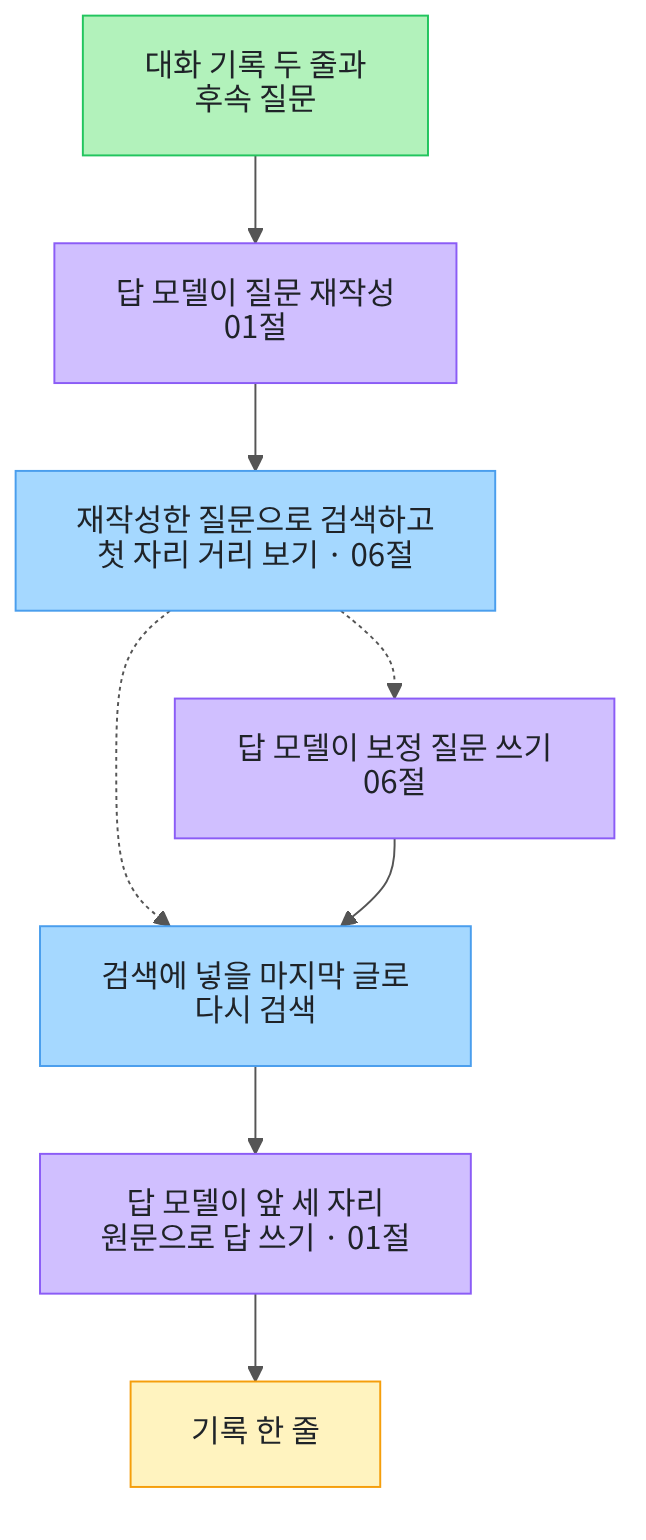

위에서 아래로 읽습니다.
맨 위 초록 상자가 우리가 넣는 재료이고 맨 아래 노란 상자가 출력으로 확인하는 값입니다.
보라 상자 셋이 답 모델을 부르는 자리이고 파란 상자 둘이 코드가 하는 일입니다.
가운데에서 점선 둘로 갈라지는데 오른쪽 갈래만 답 모델을 한 번 더 부릅니다.

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01~09절에서 쓴 이름과 문법만 쓰고 따로 내는 과제는 없습니다.
첫 셀은 패키지 네 개를 설치하고 설치된 판 번호를 출력합니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.1" "python-dotenv==1.2.3" "numpy==2.5.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.1
python-dotenv: 1.2.3
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 판 번호 네 줄이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다.
이 노트북의 출력은 2026-09-21에 이 판으로 실행한 결과입니다.

다음 셀은 이름 네 개를 불러오고 도구 파일에서 함수 일곱 개를 가져옵니다.
앞의 둘은 자료 읽기와 폴더 확인에 씁니다.
뒤의 둘은 01~09절에서 쓴 임베딩과 답 모델 이름입니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 01절 `build_rewrite_prompt()`·`build_answer_prompt()`·`keeps_word()`를 가져옵니다.
06절 `search_hits()`·`correct_once()`와 Ch 11 01절 `unique_doc_ids()`·`find_gold_rank()`도 가져옵니다.
02절 줄 나누기와 06절 판정 규칙·보정 머리글은 `correct_once()` 안에서 불립니다.
인자 모양은 8절과 9절에서 설명합니다.

In [2]:
# 자료 읽기·폴더 확인과 임베딩·답 모델 이름을 불러옵니다
import json
import os

from langchain_openai import OpenAIEmbeddings
from langchain.chat_models import init_chat_model
# 01·06절 함수와 Ch 11 01절 함수를 도구 파일에서 가져옵니다
from rag_tools import build_answer_prompt, build_rewrite_prompt, correct_once
from rag_tools import find_gold_rank, keeps_word, search_hits, unique_doc_ids

print("불러온 이름:", "json", "os", "OpenAIEmbeddings", "init_chat_model")

불러온 이름: json os OpenAIEmbeddings init_chat_model


**결과 읽기** — 출력 줄에 불러온 이름 네 개가 보입니다.
09절과 달리 `hashlib`이 없습니다.
이 절은 파일을 쓰지 않기 때문입니다.
도구 파일에서 가져온 함수 일곱 개는 출력하지 않습니다.

## 2. 키와 모델 준비

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 3. 문서와 질문 읽기

이 절은 01~09절과 같은 문서 파일과 질문 파일을 읽습니다.
먼저 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.

In [5]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch14-rag-patterns/data"):
        root_path = candidate
        break
print("고른 자리:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 자리: .


**결과 읽기** — 출력 줄 `고른 자리` 뒤에 점 하나나 위로 올라가는 표시가 보입니다.
01~09절에서 쓴 방법과 같습니다.

다음 셀은 문서 파일과 질문 파일을 읽습니다.

In [6]:
# 이 챕터 폴더의 문서 파일과 질문 파일을 읽습니다(읽기만 하고 고치지 않습니다)
data_path = root_path + "/labs/part4/ch14-rag-patterns/data"
with open(data_path + "/documents.json", encoding="utf-8") as file:
    docs = json.loads(file.read())
with open(data_path + "/queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
print("문서 수:", len(docs))
print("질문 수:", len(queries))

문서 수: 12
질문 수: 8


**결과 읽기** — 출력 줄 `문서 수: 12`와 `질문 수: 8`이 01~09절과 같습니다.

자료의 질문 여덟 개는 모두 혼자서도 뜻이 통하는 질문입니다.
그래서 대화 기록이 있어야 뜻이 정해지는 후속 질문이 자료에 없습니다.
이 실습은 상담 대화 두 줄과 후속 질문 둘을 손으로 적습니다.
정답 문서는 자료에 있는 문서에서 고릅니다.

## 4. 값 정하기

다음 셀은 01~09절에서 쓰던 값 둘을 그대로 적는 준비 셀입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.

In [7]:
# 01~09절에서 쓰던 값 둘을 그대로 적습니다
top_three = 3
top_all = 12
print("답에 넣을 상위 문서 수:", top_three)
print("자리를 셀 때 재는 문서 수:", top_all)

답에 넣을 상위 문서 수: 3
자리를 셀 때 재는 문서 수: 12


다음 셀은 06절 보정 검색에 쓸 값 둘과 미리 세어 둔 요청 수를 적습니다.
거리 기준값은 06절에서 `0.65`였고 이 실습은 `0.5`로 다시 잡았습니다.
06절은 자료 질문을 그대로 검색했고 이 실습은 재작성한 질문으로 검색합니다.
두 갈래가 모두 보이도록 탐색 실행 뒤에 정한 값입니다.

In [8]:
# 06절 보정 검색에 쓸 값 둘과 미리 세어 둔 요청 수를 적습니다
distance_limit = 0.5
retry_limit = 1
expected_calls = 10
print("거리 기준값:", distance_limit)
print("다시 검색할 수 있는 횟수 상한:", retry_limit)
print("미리 세어 둔 서비스 요청 수:", expected_calls)

거리 기준값: 0.5
다시 검색할 수 있는 횟수 상한: 1
미리 세어 둔 서비스 요청 수: 10


**결과 읽기** — 출력 줄 `거리 기준값: 0.5`가 다시 검색할지 가르는 값입니다.
출력 줄 `다시 검색할 수 있는 횟수 상한: 1`은 06절 값 그대로입니다.
출력 줄 `미리 세어 둔 서비스 요청 수: 10`은 마지막 셀에서 실제로 센 수와 견줍니다.

거리는 작을수록 가깝습니다.
첫 자리 거리가 기준값보다 크면 한 번만 다시 검색합니다.

## 5. 상담 대화와 후속 질문 정하기

이용자가 도우미와 두 줄을 주고받은 뒤에 짧게 묻는 상황입니다.
두 후속 질문은 모두 반납이 늦을 때 무슨 일이 생기는지 묻습니다.
그래서 정답 문서는 둘 다 같습니다.

In [9]:
# 상담 대화 두 줄과 말이 빠진 후속 질문 둘을 정합니다
history_lines = []
history_lines.append("사용자: 일반 도서는 며칠 동안 빌릴 수 있나요?")
history_lines.append("도우미: 일반 도서는 14일 동안 대출할 수 있습니다.")
first_follow_up = "늦으면 어떻게 되나요?"
second_follow_up = "그날 못 가져오면 돈 내야 하나요?"
gold_doc_id = "LIB-002"
print("대화 기록 줄 수:", len(history_lines))
print("실행 1의 후속 질문:", first_follow_up)
print("실행 2의 후속 질문:", second_follow_up)
print("두 후속 질문의 정답 문서 ID:", gold_doc_id)

대화 기록 줄 수: 2
실행 1의 후속 질문: 늦으면 어떻게 되나요?
실행 2의 후속 질문: 그날 못 가져오면 돈 내야 하나요?
두 후속 질문의 정답 문서 ID: LIB-002


**결과 읽기** — 출력 줄 `대화 기록 줄 수: 2`로 앞선 대화가 두 줄입니다.
출력 줄 `실행 1의 후속 질문: 늦으면 어떻게 되나요?`에는 무엇이 늦는지가 없습니다.
출력 줄 `실행 2의 후속 질문: 그날 못 가져오면 돈 내야 하나요?`에는 그날이 어느 날인지가 없습니다.
출력 줄 `두 후속 질문의 정답 문서 ID: LIB-002`가 두 실행에서 같게 두는 정답입니다.

둘 다 대화 기록을 봐야 뜻이 정해지는 후속 질문입니다.
다만 실행 2의 질문에는 돈이라는 말이 들어 있어 묻는 내용이 더 좁습니다.

## 6. 앞 절 부품 준비

다음 두 셀은 01~09절에서 이미 본 준비입니다.
읽지 말고 실행만 하고 넘어가도 됩니다.
첫 셀은 문서 글과 문서 ID와 글의 짝을 만들고 둘째 셀은 01절 머리글 둘을 적습니다.
앞 절 함수는 준비 셀에서 도구 파일로 가져왔습니다.

In [10]:
# 문서 12개의 제목과 본문을 이어 붙이고 문서 ID로 그 글을 찾을 짝도 만듭니다
doc_texts = []
doc_ids = []
for doc in docs:
    doc_texts.append(doc["title"] + " " + doc["text"])
    doc_ids.append(doc["doc_id"])
text_by_doc = {}
for i in range(len(doc_ids)):
    text_by_doc[doc_ids[i]] = doc_texts[i]
print("이어 붙인 글 수:", len(doc_texts))
print("문서 ID와 글의 짝 수:", len(text_by_doc))

이어 붙인 글 수: 12
문서 ID와 글의 짝 수: 12


In [11]:
# 01절 머리글 둘을 01절과 같게 적습니다
rewrite_head = "아래 대화 기록을 보고 마지막 질문을 혼자서도 뜻이 통하는 검색 질문 한 문장으로 바꾸세요.\n"
rewrite_head = rewrite_head + "새 조건을 보태지 말고 질문 한 문장만 적으세요.\n\n"
answer_head = "아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.\n"
answer_head = answer_head + "답 끝에 [문서ID] 모양으로 출처를 적으세요.\n\n"
print("재작성 머리글:")
print(rewrite_head)
print("답 만들기 머리글:")
print(answer_head)

재작성 머리글:
아래 대화 기록을 보고 마지막 질문을 혼자서도 뜻이 통하는 검색 질문 한 문장으로 바꾸세요.
새 조건을 보태지 말고 질문 한 문장만 적으세요.


답 만들기 머리글:
아래 자료만 보고 질문에 한국어로 한 문장으로 답하세요.
답 끝에 [문서ID] 모양으로 출처를 적으세요.




준비 셀 두 개를 지났습니다.
머리글 둘은 01절과 같고 06절 보정 질문 머리글은 도구 파일의 `build_fix_prompt()` 안에 있습니다.
같은 머리글을 써야 앞 절과 같은 조건이 됩니다.
02절 변형 질문과 05절 가상 문서와 07절 근거 검사와 08절 갈래 요약은 가져오지 않았습니다.

## 7. 문서를 벡터로 바꾸기

다음 셀은 문서 열두 건을 벡터로 바꿉니다.
이 절에서 서비스에 보내는 첫 요청입니다.

In [12]:
# Ch 12와 같은 모델로 문서 12개를 벡터로 바꿉니다(임베딩 요청 1번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
doc_vectors = embedding_model.embed_documents(doc_texts)
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 벡터 수:", len(doc_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 벡터 수: 12


**결과 읽기** — 출력 줄 `임베딩 모델 이름: text-embedding-3-small`은 01~09절과 같은 모델입니다.
출력 줄 `벡터의 숫자 개수 설정: 256`도 Ch 10~13과 같은 값입니다.
출력 줄 `문서 벡터 수: 12`로 문서마다 벡터 하나를 받았습니다.

문서 벡터는 한 번만 만들어 두 실행이 함께 씁니다.

## 8. 앞 절 기능을 함수로 묶기

앞 절 기능 둘을 함수 하나씩으로 묶습니다.
첫 함수는 01절 질문 재작성입니다.

In [13]:
# 01절 질문 재작성을 함수 하나로 묶습니다(부를 때마다 답 모델 요청 1번)
def rewrite_question(history_lines, question):
    rewrite_prompt = build_rewrite_prompt(rewrite_head, history_lines, question)
    rewrite_reply = model.invoke(rewrite_prompt)
    rewritten = rewrite_reply.text.strip()
    return rewritten

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `rewrite_question`은 대화 기록과 마지막 질문을 한 글로 이어 답 모델에 넣습니다.
받은 답에서 앞뒤 빈칸을 없앤 글이 재작성한 질문입니다.
01절과 같은 머리글을 쓰므로 01절과 같은 조건입니다.
가져온 `build_rewrite_prompt()`는 재작성 머리글을 첫 인자로 받습니다.

다음 셀은 01절 답 만들기입니다.

In [14]:
# 01절 답 만들기를 함수 하나로 묶습니다(부를 때마다 답 모델 요청 1번)
def write_answer(search_text, hit_list):
    answer_prompt = build_answer_prompt(answer_head, search_text, hit_list[:top_three], text_by_doc)
    answer_reply = model.invoke(answer_prompt)
    answer = answer_reply.text.strip()
    return answer

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `write_answer`는 검색한 목록에서 앞 세 자리만 골라 원문을 넣습니다.
답 머리글이 답 끝에 문서 ID 표시를 붙이라고 적고 있습니다.
가져온 `build_answer_prompt()`는 답 머리글을 첫 인자로, 문서 ID와 글의 짝을 넷째 인자로 받습니다.
드는 서비스 요청은 답 모델 한 번입니다.

## 9. 흐름 하나로 잇기

이제 두 함수와 06절 보정 검색을 한 흐름으로 잇습니다.
앞 흐름은 재작성과 검색과 판정과 보정까지입니다.

In [15]:
# 01절 재작성과 06절 보정 검색을 앞 흐름 하나로 잇습니다
def prepare_search(history_lines, question):
    rewritten = rewrite_question(history_lines, question)
    first_hits = search_hits(embedding_model, rewritten, doc_vectors, doc_ids, top_all)
    first_ids = unique_doc_ids(first_hits)
    row = correct_once(model, rewritten, first_hits[0]["거리"], distance_limit)
    row["재작성한 질문"] = rewritten
    row["첫 검색의 첫 자리 거리"] = first_hits[0]["거리"]
    row["첫 검색의 정답 자리"] = find_gold_rank(first_ids, [gold_doc_id])
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `prepare_search`는 재작성한 질문으로 한 번 검색하고 첫 자리 거리를 봅니다.
그 거리를 06절 규칙에 넣어 다시 검색할지 정합니다.

가져온 `search_hits()`는 임베딩 모델을 첫 인자로 받고 `correct_once()`는 답 모델을 첫 인자로 받습니다.
멀다고 나온 갈래에서만 답 모델이 보정 질문을 씁니다.
첫 검색의 정답 자리도 함께 적어 두어 뒤에서 견줄 수 있게 합니다.

다음 셀은 뒤 흐름입니다.

In [16]:
# 앞 흐름이 고른 글로 다시 검색하고 01절 답 만들기까지 잇습니다
def answer_once(history_lines, question):
    row = prepare_search(history_lines, question)
    final_hits = search_hits(embedding_model, row["보정 질문"], doc_vectors, doc_ids, top_all)
    final_ids = unique_doc_ids(final_hits)
    row["마지막 검색의 첫 자리 문서"] = final_ids[0]
    row["마지막 검색의 첫 자리 거리"] = final_hits[0]["거리"]
    row["마지막 검색의 정답 자리"] = find_gold_rank(final_ids, [gold_doc_id])
    row["답"] = write_answer(row["보정 질문"], final_hits)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `answer_once`는 앞 흐름이 고른 마지막 글로 다시 검색합니다.
보정으로 가지 않은 갈래에서는 같은 글을 다시 검색하므로 결과가 같습니다.
갈래마다 코드가 달라지지 않아 흐름이 한 줄로 읽힙니다.
마지막으로 앞 세 자리 원문을 넣어 답을 받습니다.

다음 셀은 실행 한 번을 표 한 줄로 만드는 기록 장치입니다.

In [17]:
# 실행 한 번을 기록 한 줄로 만듭니다(06절 기록 판에서 자리 칸을 둘로 나누고 첫 자리 문서 칸을 뺐습니다)
def run_row(run_name, follow_up, result):
    row = {"실행": run_name}
    row["후속 질문"] = follow_up
    row["첫 검색의 첫 자리 거리"] = result["첫 검색의 첫 자리 거리"]
    row["다시 검색한 횟수"] = result["다시 검색한 횟수"]
    row["첫 검색의 정답 자리"] = result["첫 검색의 정답 자리"]
    row["마지막 검색의 정답 자리"] = result["마지막 검색의 정답 자리"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_row`는 06절 기록 판에서 자리 칸을 둘로 나누고 첫 자리 문서 칸을 뺀 것입니다.
칸은 실행 이름과 후속 질문과 첫 자리 거리와 다시 검색한 횟수입니다.
거기에 첫 검색의 정답 자리와 마지막 검색의 정답 자리를 더합니다.

## 10. 실행 1

실행 전에 예상해 봅니다.
후속 질문이 짧아 재작성한 질문도 넓게 나올 것입니다.
그러면 첫 자리 거리가 기준값보다 멀어 한 번 더 검색할 것입니다.

In [18]:
# 실행 1은 대화 기록 두 줄과 첫 후속 질문으로 흐름 전체를 지납니다(서비스 요청 다섯 번)
run1 = answer_once(history_lines, first_follow_up)
print("후속 질문:", first_follow_up)
print("재작성한 질문:", run1["재작성한 질문"])
print("첫 검색의 첫 자리 거리:", run1["첫 검색의 첫 자리 거리"])
print("거리 기준값:", distance_limit)
print("다시 검색한 횟수:", run1["다시 검색한 횟수"])
print("검색에 넣은 마지막 글:", run1["보정 질문"])

후속 질문: 늦으면 어떻게 되나요?
재작성한 질문: 도서 반납이 늦으면 어떻게 되나요?
첫 검색의 첫 자리 거리: 0.6
거리 기준값: 0.5
다시 검색한 횟수: 1
검색에 넣은 마지막 글: 도서 반납이 지연되면 어떻게 됩니까?


**결과 읽기** — 출력 줄 `첫 검색의 첫 자리 거리: 0.6`이 기준값 `0.5`보다 큽니다.
그래서 출력 줄 `다시 검색한 횟수: 1`이 되었습니다.
출력 줄 `검색에 넣은 마지막 글` 뒤에 답 모델이 쓴 보정 질문이 있습니다.

보정 질문에서는 「늦으면」이라는 일상 말이 「지연되면」으로 바뀌었습니다.
재작성한 질문과 보정 질문의 문장은 실행마다 달라질 수 있습니다.
다음 셀은 이 실행의 마지막 검색 결과와 답을 봅니다.

In [19]:
# 실행 1의 마지막 검색 결과와 모델이 쓴 답을 봅니다
print("마지막 검색의 첫 자리 문서:", run1["마지막 검색의 첫 자리 문서"])
print("마지막 검색의 첫 자리 거리:", run1["마지막 검색의 첫 자리 거리"])
print("첫 검색의 정답 자리:", run1["첫 검색의 정답 자리"])
print("마지막 검색의 정답 자리:", run1["마지막 검색의 정답 자리"])
print("답에 정답 문서 ID 표시가 있는가:", keeps_word(run1["답"], gold_doc_id))
print("모델이 쓴 답:")
print(run1["답"])

마지막 검색의 첫 자리 문서: LIB-001
마지막 검색의 첫 자리 거리: 0.56
첫 검색의 정답 자리: 2
마지막 검색의 정답 자리: 2
답에 정답 문서 ID 표시가 있는가: True
모델이 쓴 답:
반납 예정일을 넘기면 연체한 날짜만큼 새 대출이 제한되며 연체료는 부과되지 않습니다. [LIB-002]


**결과 읽기** — 출력 줄 `첫 검색의 정답 자리: 2`가 보정 전 자리입니다.
출력 줄 `마지막 검색의 정답 자리: 2`가 보정 뒤 자리입니다.
이번 실행에서는 자리 숫자가 그대로였습니다.

출력 줄 `마지막 검색의 첫 자리 거리: 0.56`은 첫 검색보다 작습니다.
그런데 출력 줄 `마지막 검색의 첫 자리 문서: LIB-001`은 정답 문서가 아닙니다.
거리가 줄어도 정답 문서가 앞으로 온다고 볼 수 없는 자리입니다.
탐색 실행에서는 같은 후속 질문의 보정 뒤 정답 문서가 첫 자리였습니다.
보정 뒤 자리는 보정 질문 문장에 따라 달라지는 값이라 결론에 쓰지 않습니다.

출력 줄 `답에 정답 문서 ID 표시가 있는가: True`로 답 끝에 정답 문서 표시가 붙었습니다.
마지막 검색의 앞 세 자리 안에 정답 문서가 들어 있었기 때문입니다.
답 문장과 이 확인 줄도 실행마다 달라질 수 있습니다.

## 11. 실행 2

바꾸는 값은 후속 질문 하나입니다.
대화 기록과 거리 기준값과 문서와 정답 문서와 모델은 그대로 둡니다.
실행 전에 예상해 봅니다.
질문에 돈이라는 말이 있어 재작성한 질문이 더 좁아질 것입니다.

In [20]:
# 실행 2는 후속 질문만 바꾸고 대화 기록과 기준값은 그대로 둡니다(서비스 요청 네 번)
run2 = answer_once(history_lines, second_follow_up)
print("후속 질문:", second_follow_up)
print("재작성한 질문:", run2["재작성한 질문"])
print("첫 검색의 첫 자리 거리:", run2["첫 검색의 첫 자리 거리"])
print("거리 기준값:", distance_limit)
print("다시 검색한 횟수:", run2["다시 검색한 횟수"])
print("검색에 넣은 마지막 글:", run2["보정 질문"])

후속 질문: 그날 못 가져오면 돈 내야 하나요?
재작성한 질문: 그날 못 가져오면 연체료를 내야 하나요?
첫 검색의 첫 자리 거리: 0.37
거리 기준값: 0.5
다시 검색한 횟수: 0
검색에 넣은 마지막 글: 그날 못 가져오면 연체료를 내야 하나요?


**결과 읽기** — 출력 줄 `첫 검색의 첫 자리 거리: 0.37`이 기준값 `0.5`보다 작습니다.
그래서 출력 줄 `다시 검색한 횟수: 0`이 되었습니다.
출력 줄 `검색에 넣은 마지막 글` 뒤에 재작성한 질문이 그대로 있습니다.

보정 갈래로 가지 않아 답 모델 요청이 한 번 줄었습니다.
다음 셀은 이 실행의 마지막 검색 결과와 답을 봅니다.

In [21]:
# 실행 2의 마지막 검색 결과와 모델이 쓴 답을 봅니다
print("마지막 검색의 첫 자리 문서:", run2["마지막 검색의 첫 자리 문서"])
print("마지막 검색의 첫 자리 거리:", run2["마지막 검색의 첫 자리 거리"])
print("첫 검색의 정답 자리:", run2["첫 검색의 정답 자리"])
print("마지막 검색의 정답 자리:", run2["마지막 검색의 정답 자리"])
print("답에 정답 문서 ID 표시가 있는가:", keeps_word(run2["답"], gold_doc_id))
print("모델이 쓴 답:")
print(run2["답"])

마지막 검색의 첫 자리 문서: LIB-002
마지막 검색의 첫 자리 거리: 0.37
첫 검색의 정답 자리: 1
마지막 검색의 정답 자리: 1
답에 정답 문서 ID 표시가 있는가: True
모델이 쓴 답:
아니요, 반납 예정일을 넘겨도 연체료는 부과하지 않습니다. [LIB-002]


**결과 읽기** — 출력 줄 `첫 검색의 정답 자리: 1`과 `마지막 검색의 정답 자리: 1`이 같습니다.
보정으로 가지 않아 같은 글을 다시 검색했기 때문입니다.
출력 줄 `마지막 검색의 첫 자리 거리: 0.37`도 첫 검색과 같습니다.

출력 줄 `답에 정답 문서 ID 표시가 있는가: True`는 실행 1과 같았습니다.
답 문장은 실행마다 달라질 수 있어 낱말을 확인 줄로 보지 않습니다.

## 12. 두 실행 견주기

마지막으로 두 실행의 기록을 한 표로 모읍니다.
실행 전에 예상해 봅니다.
한 번 더 검색한 실행 1의 자리가 앞으로 올 것이라고 기대하기 쉽습니다.

In [22]:
# 두 실행의 기록을 담아 라벨 줄 아래에 한 줄씩 출력합니다
run_rows = []
run_rows.append(run_row("실행 1", first_follow_up, run1))
run_rows.append(run_row("실행 2", second_follow_up, run2))
print("실행 | 첫 자리 거리 | 다시 검색한 횟수 | 첫 검색 정답 자리 | 마지막 검색 정답 자리")
for row in run_rows:
    print(row["실행"], "|", row["첫 검색의 첫 자리 거리"], "|", row["다시 검색한 횟수"], "|", row["첫 검색의 정답 자리"], "|", row["마지막 검색의 정답 자리"])
    print("  후속 질문:", row["후속 질문"])

실행 | 첫 자리 거리 | 다시 검색한 횟수 | 첫 검색 정답 자리 | 마지막 검색 정답 자리
실행 1 | 0.6 | 1 | 2 | 2
  후속 질문: 늦으면 어떻게 되나요?
실행 2 | 0.37 | 0 | 1 | 1
  후속 질문: 그날 못 가져오면 돈 내야 하나요?


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
첫 줄은 `실행 1 | 0.6 | 1 | 2 | 2`이고 둘째 줄은 `실행 2 | 0.37 | 0 | 1 | 1`입니다.
마지막 칸은 실행 1이 `2`이고 실행 2가 `1`입니다.

한 번 더 검색한 실행 1의 자리가 앞으로 오지 않았습니다.
앞의 예상과 다른 결과입니다.
다음 셀은 갈린 칸 수를 세고 반복 상한을 확인합니다.

In [23]:
# 값이 갈린 칸 수를 세고 다시 검색 상한을 넘지 않았는지 확인합니다
column_names = ["첫 검색의 첫 자리 거리", "다시 검색한 횟수", "첫 검색의 정답 자리", "마지막 검색의 정답 자리"]
changed_count = 0
for name in column_names:
    if run1[name] != run2[name]:
        changed_count = changed_count + 1
print("견준 칸 수:", len(column_names))
print("값이 갈린 칸 수:", changed_count)
assert run1["다시 검색한 횟수"] <= retry_limit, "실행 1이 다시 검색 상한을 넘었습니다."
assert run2["다시 검색한 횟수"] <= retry_limit, "실행 2가 다시 검색 상한을 넘었습니다."

견준 칸 수: 4
값이 갈린 칸 수: 4


**결과 읽기** — 출력 줄 `견준 칸 수: 4`와 `값이 갈린 칸 수: 4`가 보입니다.
네 칸이 모두 갈렸습니다.
확인 줄 둘은 두 실행 모두 반복 상한을 넘지 않았을 때 조용히 지나갑니다.

다음 셀은 서비스에 보낸 요청 수를 셉니다.

In [24]:
# 두 실행이 서비스에 보낸 요청 수를 세어 미리 세어 둔 수와 견줍니다
doc_calls = 1
base_calls = 4
run1_calls = base_calls + run1["다시 검색한 횟수"]
run2_calls = base_calls + run2["다시 검색한 횟수"]
total_calls = doc_calls + run1_calls + run2_calls
print("실행 1의 서비스 요청 수:", run1_calls)
print("실행 2의 서비스 요청 수:", run2_calls)
print("실제로 센 서비스 요청 수:", total_calls)
assert total_calls == expected_calls, "미리 세어 둔 요청 수와 다릅니다."

실행 1의 서비스 요청 수: 5
실행 2의 서비스 요청 수: 4
실제로 센 서비스 요청 수: 10


**결과 읽기** — 출력 줄 `실행 1의 서비스 요청 수: 5`와 `실행 2의 서비스 요청 수: 4`가 보입니다.
출력 줄 `실제로 센 서비스 요청 수: 10`이 미리 세어 둔 수와 같아 확인 줄이 지나갔습니다.
이 수는 고정 네 번에 실행마다 다시 검색한 횟수를 더해 센 값입니다.
차이 한 번은 실행 1이 보정 질문을 받으려고 답 모델을 한 번 더 부른 것입니다.

## 정리

1. 01절 질문 재작성과 06절 보정 검색과 01절 답 만들기를 한 흐름으로 이었습니다.
2. 후속 질문 하나만 바꾸자 지나는 갈래와 서비스 요청 수가 달라졌습니다.
3. 요청을 한 번 더 쓴 실행에서도 이번에는 정답 문서가 첫 자리로 오지 않았습니다.

이 결과는 문서 열두 건과 후속 질문 둘과 기준값 하나에서 한 번 본 것입니다.
답이 맞는지 판정하는 일은 Ch 15에서 따로 봅니다.